# Proyecto 3 · Regresión con validación cruzada: precio de la vivienda en California

**Objetivo:** predecir el valor medio de la vivienda de un distrito a partir de sus características, eligiendo el modelo con **validación cruzada** en vez de con un único reparto.

Cubre las secciones de regresión lineal y de validación cruzada y compromiso sesgo-varianza del bootcamp. La clase de regresión lineal del curso usa un dataset sintético de viviendas en EE. UU.; aquí se usa uno real con la misma idea: el censo de California de 1990, incluido en scikit-learn.

**Plan:**

1. Exploración y una decisión sobre los valores topados.
2. Regresión lineal como referencia interpretable.
3. Comparación de 4 algoritmos con validación cruzada de 5 pliegues.
4. **Sesgo-varianza:** curva de validación de la profundidad de un árbol.
5. Evaluación final del modelo elegido en un conjunto de prueba reservado desde el principio.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, KFold, cross_validate, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
SEMILLA = 42
casas = fetch_california_housing(as_frame=True).frame
print(casas.shape)
casas.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Cada fila es un **distrito censal**, no una casa. `MedHouseVal` (la etiqueta) está en cientos de miles de dólares; `MedInc` (ingreso mediano) en decenas de miles.

In [2]:
casas.describe().round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


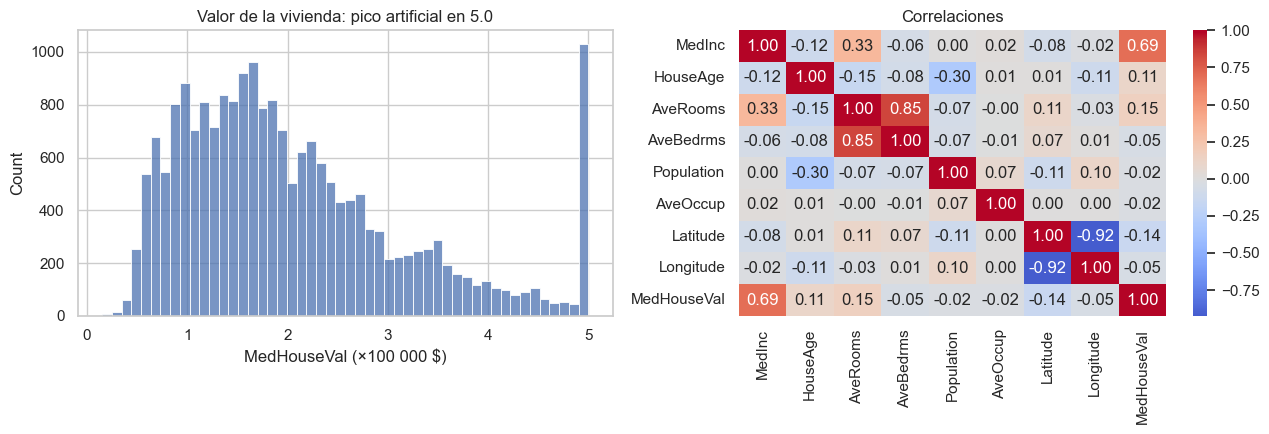

Distritos con el valor topado en 5.0: 992 (4.8%)


In [3]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(casas['MedHouseVal'], bins=50, ax=izq)
izq.set_title('Valor de la vivienda: pico artificial en 5.0'); izq.set_xlabel('MedHouseVal (×100 000 $)')
sns.heatmap(casas.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=der)
der.set_title('Correlaciones')
plt.tight_layout()
plt.savefig('../imagenes/regresion-exploracion.png', dpi=110, bbox_inches='tight')
plt.show()
print(f"Distritos con el valor topado en 5.0: {(casas['MedHouseVal'] >= 5.0).sum()} ({(casas['MedHouseVal'] >= 5.0).mean():.1%})")

**Decisión sobre el tope.** El censo registró como 5.0 todos los valores de 500 000 $ o más. Esos distritos no tienen su valor real, sino un techo. Si se dejan, el modelo aprende que "nada vale más de 500 000 $" y se le penaliza por predecir más en distritos que de verdad valen más. Como son un ~5% de los datos, se excluyen. Queda documentado: el modelo no sirve para distritos de lujo.

In [4]:
casas = casas[casas['MedHouseVal'] < 5.0]
X = casas.drop(columns='MedHouseVal')
y = casas['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print(f'Entrenamiento: {len(X_train)} · Prueba (reservada hasta el final): {len(X_test)}')

Entrenamiento: 15718 · Prueba (reservada hasta el final): 3930


## Referencia: regresión lineal

Antes de comparar nada, el modelo más interpretable. Cada coeficiente indica cuánto cambia el valor predicho por cada unidad de esa feature, con las demás fijas.

In [5]:
lineal = LinearRegression().fit(X_train, y_train)
pd.Series(lineal.coef_, index=X.columns).round(4).to_frame('coeficiente')

,coeficiente
MedInc,0.4283
HouseAge,0.0080
AveRooms,-0.1036
AveBedrms,0.5788
Population,0.0000
AveOccup,-0.0031
Latitude,-0.3758
Longitude,-0.3922


## Comparación con validación cruzada (5 pliegues)

Todo dentro de un `Pipeline`: el escalado (que KNN necesita) se ajusta en cada pliegue solo con sus datos de entrenamiento.

In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
escalar = lambda m: Pipeline([('escala', StandardScaler()), ('modelo', m)])
candidatos = {
    'Media (línea base)': DummyRegressor(),
    'Regresión lineal': LinearRegression(),
    'KNN (k=10)': escalar(KNeighborsRegressor(n_neighbors=10)),
    'Árbol de decisión': DecisionTreeRegressor(random_state=SEMILLA),
    'Bosque aleatorio': RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=-1),
}

filas = []
for nombre, modelo in candidatos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, return_train_score=True,
                       scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2', 'mae': 'neg_mean_absolute_error'})
    filas.append({'Modelo': nombre,
                  'RMSE entrenamiento': -r['train_rmse'].mean(),
                  'RMSE validación': -r['test_rmse'].mean(),
                  'RMSE desv.': r['test_rmse'].std(),
                  'MAE validación': -r['test_mae'].mean(),
                  'R² validación': r['test_r2'].mean()})
tabla_cv = pd.DataFrame(filas).set_index('Modelo').sort_values('RMSE validación')
tabla_cv.round(3)

,RMSE entrenamiento,RMSE validación,RMSE desv.,MAE validación,R² validación
Modelo,,,,,
Bosque aleatorio,0.172,0.461,0.008,0.311,0.773
KNN (k=10),0.519,0.577,0.015,0.408,0.646
Regresión lineal,0.631,0.634,0.012,0.472,0.572
Árbol de decisión,0.000,0.657,0.008,0.437,0.540
Media (línea base),0.969,0.969,0.006,0.777,-0.000


La columna **RMSE entrenamiento** es tan importante como la de validación: la distancia entre ambas mide el **sobreajuste**.

## Sesgo-varianza: curva de validación del árbol de decisión

Un árbol sin límite memoriza el entrenamiento. Variando su profundidad máxima se ve el compromiso completo: poca profundidad → error alto en ambos conjuntos (sesgo); mucha → error casi nulo en entrenamiento pero creciente en validación (varianza).

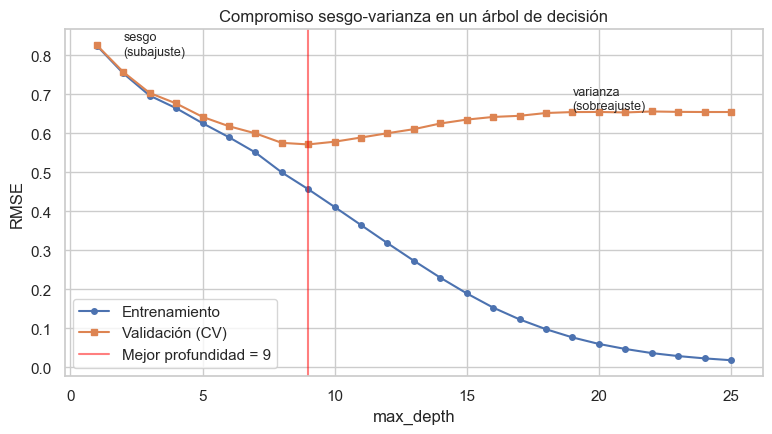

Mejor profundidad: 9 · RMSE validación 0.571 (frente a 0.655 con profundidad 25)


In [7]:
profundidades = np.arange(1, 26)
tr, va = validation_curve(DecisionTreeRegressor(random_state=SEMILLA), X_train, y_train,
                          param_name='max_depth', param_range=profundidades, cv=cv,
                          scoring='neg_root_mean_squared_error')
tr, va = -tr.mean(axis=1), -va.mean(axis=1)
p_mejor = int(profundidades[np.argmin(va)])

plt.figure(figsize=(9, 4.5))
plt.plot(profundidades, tr, 'o-', markersize=4, label='Entrenamiento')
plt.plot(profundidades, va, 's-', markersize=4, label='Validación (CV)')
plt.axvline(p_mejor, color='red', alpha=0.5, label=f'Mejor profundidad = {p_mejor}')
plt.text(2, va.max() * 0.97, 'sesgo\n(subajuste)', fontsize=9)
plt.text(19, va.max() * 0.80, 'varianza\n(sobreajuste)', fontsize=9)
plt.xlabel('max_depth'); plt.ylabel('RMSE'); plt.title('Compromiso sesgo-varianza en un árbol de decisión')
plt.legend()
plt.savefig('../imagenes/regresion-sesgo-varianza.png', dpi=110, bbox_inches='tight')
plt.show()
print(f'Mejor profundidad: {p_mejor} · RMSE validación {va.min():.3f} (frente a {va[-1]:.3f} con profundidad 25)')

## Evaluación final en el conjunto de prueba

Se entrenan con todo el entrenamiento la regresión lineal (referencia), el árbol con la profundidad elegida y el mejor modelo de la validación cruzada. Se evalúan **una sola vez** sobre la prueba.

In [8]:
finales = {
    'Regresión lineal': LinearRegression(),
    f'Árbol (max_depth={p_mejor})': DecisionTreeRegressor(max_depth=p_mejor, random_state=SEMILLA),
    'Bosque aleatorio': RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=-1),
}
filas, preds = [], {}
for nombre, modelo in finales.items():
    pred = modelo.fit(X_train, y_train).predict(X_test)
    preds[nombre] = pred
    mse = mean_squared_error(y_test, pred)
    filas.append({'Modelo': nombre, 'MAE': mean_absolute_error(y_test, pred), 'MSE': mse,
                  'RMSE': np.sqrt(mse), 'R²': r2_score(y_test, pred)})
tabla_test = pd.DataFrame(filas).set_index('Modelo').sort_values('RMSE')
tabla_test.round(3)

,MAE,MSE,RMSE,R²
Modelo,,,,
Bosque aleatorio,0.311,0.216,0.465,0.774
Árbol (max_depth=9),0.402,0.335,0.579,0.651
Regresión lineal,0.483,0.413,0.643,0.569


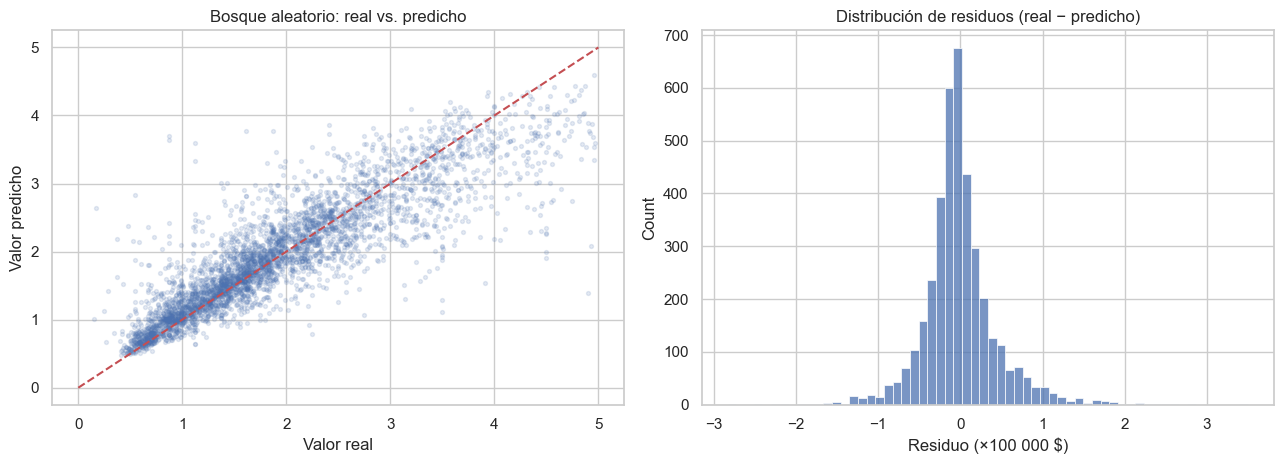

Error típico (RMSE): 46,512 $


In [9]:
mejor = tabla_test.index[0]
residuos = y_test - preds[mejor]
fig, (izq, der) = plt.subplots(1, 2, figsize=(13, 4.8))
izq.scatter(y_test, preds[mejor], alpha=0.15, s=8)
izq.plot([0, 5], [0, 5], 'r--')
izq.set_xlabel('Valor real'); izq.set_ylabel('Valor predicho'); izq.set_title(f'{mejor}: real vs. predicho')
sns.histplot(residuos, bins=60, ax=der)
der.set_title('Distribución de residuos (real − predicho)'); der.set_xlabel('Residuo (×100 000 $)')
plt.tight_layout()
plt.savefig('../imagenes/regresion-residuos.png', dpi=110, bbox_inches='tight')
plt.show()
print(f'Error típico (RMSE): {tabla_test.loc[mejor, "RMSE"] * 100_000:,.0f} $')

## Conclusiones

- **Datos:** se excluyeron 992 distritos (4.8%) con el valor topado en 500 000 $. El modelo no es válido para distritos por encima de ese valor.
- **Modelo elegido: bosque aleatorio.** Es el mejor en validación cruzada (RMSE 0.461, R² 0.773), con una desviación entre pliegues muy baja (0.008). En la prueba da RMSE 0.465 y R² 0.774: un error típico de unos **46 500 $**.
- **La validación cruzada anticipó bien el resultado.** Su RMSE estimado (0.461) quedó prácticamente igual que el de la prueba (0.465), y el orden de los modelos se mantuvo. Para eso sirve: estimar con fiabilidad cómo se comportará el modelo con datos nuevos sin gastar la prueba.
- **Sobreajuste visible en la tabla:** el árbol sin límite tiene error 0.000 en entrenamiento y 0.657 en validación. Memorizó los datos. El bosque aleatorio también sobreajusta (0.172 frente a 0.461), pero aun así es el que mejor generaliza.
- **Sesgo-varianza:** limitar el árbol a profundidad 9 baja su RMSE de validación de 0.655 a 0.571. Por debajo de 9 falta capacidad (sesgo); por encima, el error de entrenamiento sigue cayendo mientras el de validación sube (varianza).
- **La regresión lineal se queda corta** (R² 0.57) pero se puede leer: cada 10 000 $ más de ingreso mediano suman unos 43 000 $ al valor. Los coeficientes negativos de latitud y longitud indican que el valor baja hacia el norte y hacia el este, lejos de la costa sur. Los de `AveRooms` y `AveBedrms` tienen signos opuestos porque ambas variables están muy relacionadas entre sí. Por separado no se deben interpretar.
- **Los residuos** se concentran en 0, pero el modelo tiende a sobrestimar los distritos baratos y a subestimar los caros. Es la regresión hacia la media típica de un bosque aleatorio, que predice promedios de árboles.